In [1]:
import matplotlib.pyplot as plt

from Bio import SeqIO, pairwise2
from Bio.Seq import Seq
from Bio.SeqUtils import seq3
from Bio.SeqUtils import gc_fraction
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import molecular_weight as mw
from Bio.pairwise2 import format_alignment
from Levenshtein import distance
from collections import Counter

C:\Users\jorda\Code\ml-notebooks\projects\sequence-alignment\.venv\Lib\site-packages\Bio\pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
from io import StringIO

from Bio import Entrez, SeqIO

Entrez.email = "your.email@example.com"  # NCBI asks for a contact address


def fetch_record(accession, rettype="fasta"):
    """Download a nucleotide record from NCBI and parse it."""
    with Entrez.efetch(db="nuccore", id=accession, rettype=rettype, retmode="text") as handle:
        return SeqIO.read(StringIO(handle.read()), "fasta" if rettype == "fasta" else "gb")


seq_a = fetch_record('M99367').seq
print(seq_a)

AGCTCCTAGGACCAGAGCCAGGAAGAGACTAGAAAGAAAACAGCTCGTGTCAACATGACTTCCAAACTGGCTGTTGCCTTCTTGGCAGTTTTCCTGCTTTCTGCAGCTCTCTGTGAGGCTGCAGTTCTGGCAAGAGTAAGTGCAGAACTTCGATGCCAGTGCATAAATACGCATTCCACACCTTTCCACCCCAAATTTATCAAGGAACTGAGAGTGATTGAGAGTGGACCCCACTGTGAAAATTCAGAAATCATTGTTAAGCTTGTCAATGGAAAAGAGGTCTGCCTGGACCCCAAGGAAAAGTGGGTGCAGAAGGTTGTACAGATATTTTTGAAGAGAACTGAGAAGCAACAACAACAGCAGTAACAACAACAAGCAAAAACCCATTCTCCGTGGCTCCCAAGAATTTCTCAGTAAAGATGCCAACACAACTTCAATCAAATCTACATCTATGCCTCATTCCTGTGCTGGTCAGACATAGGGTTGCCAGAGAAATCACAGGATGCCCAGTTATATTTGAATATTAAGTAAAACAATGAATTATTTCCAGTGTCCCATGCACGTTGTTCTATACTAACATTTTAAAAATTCTTCGTTGTTTGCTGTAAATTCAAATTTAGCTGGAAATCCTGTTTTGGCTTTTTGTTATTATAATTATTAATATTATTAAATCTTGCAACCCTAGGCTGCTGGCCAGCATTCACAAGTCTCTGCTCAACTGCACCTCAGTTTCTTCTTTATCCCCAAACTGGAGAAAAAGCTTCAGCCCCCATCCTACCTTGAGGACATGTGGATGTACTTTAACTTTGATTGACAGTCATGTAAAATATTTTCAAGTGTAATTTATTCACTTATTTATTATTTATATATTTATTTTAGTATCAAATAGAGTAATGTTTGTGCATGAATTTGGAGAAATGGAAAAGAAGCATTGTTGATAGGATAGTCTCATGATAGTAGTGAATTTCTATTTATTTTACATATTAAGTGGTGTATTATG

In [3]:
seq_b = fetch_record('BI431008', 'gb').seq
print(seq_b)

GTGACTGCGCACCACAACTTTCCTTCGGAGACCTCATAGGACCGGGAGTGTTTCCAGCCTTGCGGGCCACCCCAGCCTTCTGCAAAGCCTCGCCCATGCCGCCTGCGTTTTCAGGGTCCTGCTCAGCTCTGACCCTGAAGTCATCTCCAGTGCTTTCCTCTTCTTCTAAGGGCCATGGCATGGCTTCATGTAATACAGATTTGGGGCAGATC


In [4]:
seq_c = seq_a[-40:][::-1]
print(seq_c)

AAAAAAAAACTGAAAATATTATTTAAAATAACATTTACAA


In [5]:
seq_d = seq_b[:50]
print(seq_d)

GTGACTGCGCACCACAACTTTCCTTCGGAGACCTCATAGGACCGGGAGTG


In [6]:
alignment = pairwise2.align.localxx(seq_c, seq_d)
for a in alignment:
    print(format_alignment(*a))

9 ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A
  ||||    |  | | | || |  ||     | |  |  ||  ||   |     |
4 ACTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGA
  Score=22

8 AACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A
  | |||    |  | | | || |  ||     | |  |  ||  ||   |     |
4 A-CTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGA
  Score=22

7 AAACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A
  |  |||    |  | | | || |  ||     | |  |  ||  ||   |     |
4 A--CTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGA
  Score=22

6 AAAACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A
  |   |||    |  | | | || |  ||     | |  |  ||  ||   |     |
4 A---CTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGA
  Score=22

5 AAAAACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A
  |    |||    |  | | | || |  ||     | |  |  ||  ||   |     |
4 A----CTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGA
  Score=22

4 AAAAAACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A

In [7]:
alignment = pairwise2.align.globalxx(seq_c, seq_d)
for a in alignment:
    print(format_alignment(*a))

AAAAAAAA---ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A---
           ||||    |  | | | || |  ||     | |  |  ||  ||   |     |   
--------GTGACTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGAGTG
  Score=22

AAAAAAAA--ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A---
       .  ||||    |  | | | || |  ||     | |  |  ||  ||   |     |   
-------GTGACTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGAGTG
  Score=22

AAAAAAAA--ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A---
      .   ||||    |  | | | || |  ||     | |  |  ||  ||   |     |   
------G-TGACTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGAGTG
  Score=22

AAAAAAAA--ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A---
     .    ||||    |  | | | || |  ||     | |  |  ||  ||   |     |   
-----G--TGACTG-CGCACCACA-ACTT-TCCTT--CGGAGACCT--CA--TA-GGACCGGGAGTG
  Score=22

AAAAAAAA--ACTGA---A--A-ATA-TTAT--TTAA---A-A--TAACATTTAC--A-----A---
    .     ||||    |  | | | || |  ||     | |  |  ||  ||   |     | 

In [8]:
def hamming(c, d):
    mismatch = []
    for x, y in zip(c, d):
        if x != y:
            mismatch.append((x, y))
    return len(mismatch)

print(hamming(seq_c, seq_d))

30


In [9]:
print(distance(seq_c, seq_d))

33


In [10]:
mrna_c = seq_c.transcribe()
print(mrna_c)

AAAAAAAAACUGAAAAUAUUAUUUAAAAUAACAUUUACAA


In [11]:
mrna_a = seq_a.transcribe()
print(mrna_a)

AGCUCCUAGGACCAGAGCCAGGAAGAGACUAGAAAGAAAACAGCUCGUGUCAACAUGACUUCCAAACUGGCUGUUGCCUUCUUGGCAGUUUUCCUGCUUUCUGCAGCUCUCUGUGAGGCUGCAGUUCUGGCAAGAGUAAGUGCAGAACUUCGAUGCCAGUGCAUAAAUACGCAUUCCACACCUUUCCACCCCAAAUUUAUCAAGGAACUGAGAGUGAUUGAGAGUGGACCCCACUGUGAAAAUUCAGAAAUCAUUGUUAAGCUUGUCAAUGGAAAAGAGGUCUGCCUGGACCCCAAGGAAAAGUGGGUGCAGAAGGUUGUACAGAUAUUUUUGAAGAGAACUGAGAAGCAACAACAACAGCAGUAACAACAACAAGCAAAAACCCAUUCUCCGUGGCUCCCAAGAAUUUCUCAGUAAAGAUGCCAACACAACUUCAAUCAAAUCUACAUCUAUGCCUCAUUCCUGUGCUGGUCAGACAUAGGGUUGCCAGAGAAAUCACAGGAUGCCCAGUUAUAUUUGAAUAUUAAGUAAAACAAUGAAUUAUUUCCAGUGUCCCAUGCACGUUGUUCUAUACUAACAUUUUAAAAAUUCUUCGUUGUUUGCUGUAAAUUCAAAUUUAGCUGGAAAUCCUGUUUUGGCUUUUUGUUAUUAUAAUUAUUAAUAUUAUUAAAUCUUGCAACCCUAGGCUGCUGGCCAGCAUUCACAAGUCUCUGCUCAACUGCACCUCAGUUUCUUCUUUAUCCCCAAACUGGAGAAAAAGCUUCAGCCCCCAUCCUACCUUGAGGACAUGUGGAUGUACUUUAACUUUGAUUGACAGUCAUGUAAAAUAUUUUCAAGUGUAAUUUAUUCACUUAUUUAUUAUUUAUAUAUUUAUUUUAGUAUCAAAUAGAGUAAUGUUUGUGCAUGAAUUUGGAGAAAUGGAAAAGAAGCAUUGUUGAUAGGAUAGUCUCAUGAUAGUAGUGAAUUUCUAUUUAUUUUACAUAUUAAGUGGUGUAUUAUG

In [12]:
mrna_z = mrna_c + mrna_a
print(mrna_z)

AAAAAAAAACUGAAAAUAUUAUUUAAAAUAACAUUUACAAAGCUCCUAGGACCAGAGCCAGGAAGAGACUAGAAAGAAAACAGCUCGUGUCAACAUGACUUCCAAACUGGCUGUUGCCUUCUUGGCAGUUUUCCUGCUUUCUGCAGCUCUCUGUGAGGCUGCAGUUCUGGCAAGAGUAAGUGCAGAACUUCGAUGCCAGUGCAUAAAUACGCAUUCCACACCUUUCCACCCCAAAUUUAUCAAGGAACUGAGAGUGAUUGAGAGUGGACCCCACUGUGAAAAUUCAGAAAUCAUUGUUAAGCUUGUCAAUGGAAAAGAGGUCUGCCUGGACCCCAAGGAAAAGUGGGUGCAGAAGGUUGUACAGAUAUUUUUGAAGAGAACUGAGAAGCAACAACAACAGCAGUAACAACAACAAGCAAAAACCCAUUCUCCGUGGCUCCCAAGAAUUUCUCAGUAAAGAUGCCAACACAACUUCAAUCAAAUCUACAUCUAUGCCUCAUUCCUGUGCUGGUCAGACAUAGGGUUGCCAGAGAAAUCACAGGAUGCCCAGUUAUAUUUGAAUAUUAAGUAAAACAAUGAAUUAUUUCCAGUGUCCCAUGCACGUUGUUCUAUACUAACAUUUUAAAAAUUCUUCGUUGUUUGCUGUAAAUUCAAAUUUAGCUGGAAAUCCUGUUUUGGCUUUUUGUUAUUAUAAUUAUUAAUAUUAUUAAAUCUUGCAACCCUAGGCUGCUGGCCAGCAUUCACAAGUCUCUGCUCAACUGCACCUCAGUUUCUUCUUUAUCCCCAAACUGGAGAAAAAGCUUCAGCCCCCAUCCUACCUUGAGGACAUGUGGAUGUACUUUAACUUUGAUUGACAGUCAUGUAAAAUAUUUUCAAGUGUAAUUUAUUCACUUAUUUAUUAUUUAUAUAUUUAUUUUAGUAUCAAAUAGAGUAAUGUUUGUGCAUGAAUUUGGAGAAAUGGAAAAGAAGCAUUGUUGAUAGGAUAGUCUCAUGAUAGUAG

In [13]:
protein_z = mrna_z.translate()
print(protein_z)
print(seq3(protein_z))

KKKLKILFKITFTKLLGPEPGRD*KENSSCQHDFQTGCCLLGSFPAFCSSL*GCSSGKSKCRTSMPVHKYAFHTFPPQIYQGTESD*EWTPL*KFRNHC*ACQWKRGLPGPQGKVGAEGCTDIFEEN*EATTTAVTTTSKNPFSVAPKNFSVKMPTQLQSNLHLCLIPVLVRHRVAREITGCPVIFEY*VKQ*IISSVPCTLFYTNILKILRCLL*IQI*LEILFWLFVIIIINIIKSCNPRLLASIHKSLLNCTSVSSLSPNWRKSFSPHPTLRTCGCTLTLIDSHVKYFQV*FIHLFIIYIFILVSNRVMFVHEFGEMEKKHC**DSLMIVVNFYLFYILSGVLWNYFYQGHCIMIRVARFGKLLNEQNTQLSTLLFI*NFI*TSYPTFETPSLVL*LQALLCSAVLNDVNFKLGLVFSKQQKFTRQYQ*SHFLLFILYFVQLDSHNFI*IIVCFKTNFFYLNLFLCISKEILLVFFMLQNCECNYRTFTIKFIIKVKKK
LysLysLysLeuLysIleLeuPheLysIleThrPheThrLysLeuLeuGlyProGluProGlyArgAspTerLysGluAsnSerSerCysGlnHisAspPheGlnThrGlyCysCysLeuLeuGlySerPheProAlaPheCysSerSerLeuTerGlyCysSerSerGlyLysSerLysCysArgThrSerMetProValHisLysTyrAlaPheHisThrPheProProGlnIleTyrGlnGlyThrGluSerAspTerGluTrpThrProLeuTerLysPheArgAsnHisCysTerAlaCysGlnTrpLysArgGlyLeuProGlyProGlnGlyLysValGlyAlaGluGlyCysThrAspIlePheGluGluAsnTerGluAlaThrThrThrAlaValThrThrThrSerLysAsnProPheSerValAlaProLysAsnPheSerValLysMetProThrGlnLeuGlnSerAsnLeuHisLeuCysLe

In [14]:
seq_z = mrna_z.back_transcribe()
print(seq_z)

AAAAAAAAACTGAAAATATTATTTAAAATAACATTTACAAAGCTCCTAGGACCAGAGCCAGGAAGAGACTAGAAAGAAAACAGCTCGTGTCAACATGACTTCCAAACTGGCTGTTGCCTTCTTGGCAGTTTTCCTGCTTTCTGCAGCTCTCTGTGAGGCTGCAGTTCTGGCAAGAGTAAGTGCAGAACTTCGATGCCAGTGCATAAATACGCATTCCACACCTTTCCACCCCAAATTTATCAAGGAACTGAGAGTGATTGAGAGTGGACCCCACTGTGAAAATTCAGAAATCATTGTTAAGCTTGTCAATGGAAAAGAGGTCTGCCTGGACCCCAAGGAAAAGTGGGTGCAGAAGGTTGTACAGATATTTTTGAAGAGAACTGAGAAGCAACAACAACAGCAGTAACAACAACAAGCAAAAACCCATTCTCCGTGGCTCCCAAGAATTTCTCAGTAAAGATGCCAACACAACTTCAATCAAATCTACATCTATGCCTCATTCCTGTGCTGGTCAGACATAGGGTTGCCAGAGAAATCACAGGATGCCCAGTTATATTTGAATATTAAGTAAAACAATGAATTATTTCCAGTGTCCCATGCACGTTGTTCTATACTAACATTTTAAAAATTCTTCGTTGTTTGCTGTAAATTCAAATTTAGCTGGAAATCCTGTTTTGGCTTTTTGTTATTATAATTATTAATATTATTAAATCTTGCAACCCTAGGCTGCTGGCCAGCATTCACAAGTCTCTGCTCAACTGCACCTCAGTTTCTTCTTTATCCCCAAACTGGAGAAAAAGCTTCAGCCCCCATCCTACCTTGAGGACATGTGGATGTACTTTAACTTTGATTGACAGTCATGTAAAATATTTTCAAGTGTAATTTATTCACTTATTTATTATTTATATATTTATTTTAGTATCAAATAGAGTAATGTTTGTGCATGAATTTGGAGAAATGGAAAAGAAGCATTGTTGATAGGATAGTCTCATGATAGTAG

73.33741776092742 80.28026056254394


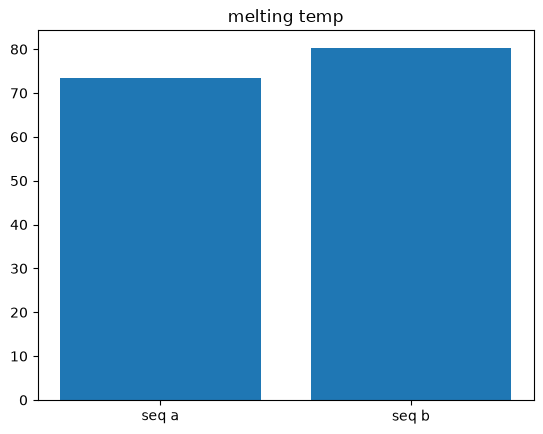

In [15]:
mt_a = mt.Tm_GC(seq_a)
mt_b = mt.Tm_GC(seq_b)
print(mt_a, mt_b)

plt.bar(['seq a', 'seq b'], [mt_a, mt_b])
plt.title('melting temp')
plt.show()

33.765347885402456 56.60377358490566


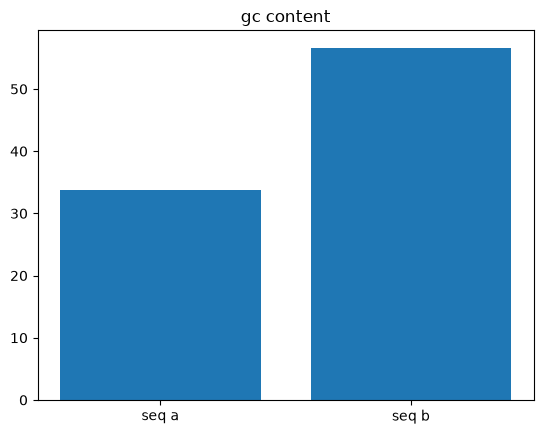

In [16]:
a_gc = gc_fraction(seq_a) * 100
b_gc = gc_fraction(seq_b) * 100
print(a_gc, b_gc)

plt.bar(['seq a', 'seq b'], [a_gc, b_gc])
plt.title('gc content')
plt.show()

452580.7299 65080.3269


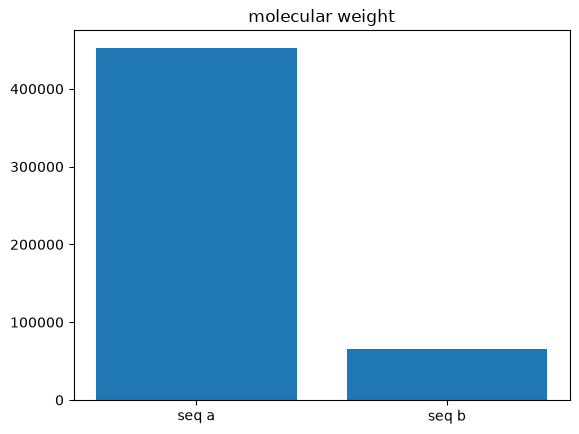

In [17]:
a_mw = mw(seq_a)
b_mw = mw(seq_b)
print(a_mw, b_mw)

plt.bar(['seq a', 'seq b'], [a_mw, b_mw])
plt.title('molecular weight')
plt.show()

Counter({'T': 516, 'A': 491, 'C': 252, 'G': 247})


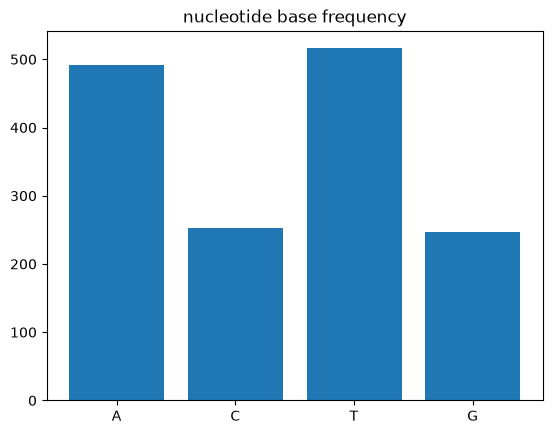

In [18]:
z_nucleotide = Counter(seq_z)
print(z_nucleotide)

plt.bar(z_nucleotide.keys(), z_nucleotide.values())
plt.title('nucleotide base frequency')
plt.show()